# UTS Machine Learning — Prediksi Skor Indeks Pelayanan Publik (IPP) 2023
**Dataset:** `ipp_2023_satudata.csv` (Indeks Pelayanan Publik 2023, SatuData)  
**Algoritma:** Regresi Linier  

Alur: (1) Pengenalan & pengolahan dataset → (2) Verifikasi perhitungan manual → (3) Implementasi model → Evaluasi.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Ubah path jika dijalankan di Google Colab / komputer lain
DATA_PATH = "ipp_2023_satudata.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "/mnt/user-data/uploads/ipp_2023_satudata.csv"
df_raw = pd.read_csv(DATA_PATH)
df_raw.head()

,nama,ipp_predikat,tahun
0,Arsip Nasional Republik Indonesia,B,2023
1,Badan Informasi Geospasial,-A,2023
2,"Badan Meteorologi, Klimatologi, dan Geofisika",D,2023
3,Badan Narkotika Nasional,-B,2023
4,Badan Nasional Penanggulangan Bencana,B,2023


## SOAL 1 — Pengenalan dan Pengolahan Dataset
### 1a. Kondisi awal data

In [2]:
print("Jumlah baris x kolom :", df_raw.shape)
print("\nTipe data:\n", df_raw.dtypes)
print("\nMissing value per kolom:\n", df_raw.isna().sum())
print("\nPersentase missing (%):\n", (df_raw.isna().mean()*100).round(2))
print("\nBaris duplikat       :", df_raw.duplicated().sum())
print("Nama instansi duplikat:", df_raw["nama"].duplicated().sum())
print("\nNilai unik tahun     :", df_raw["tahun"].unique())
print("\nDistribusi predikat IPP:")
print(df_raw["ipp_predikat"].value_counts())

Jumlah baris x kolom : (543, 3)

Tipe data:
 nama              str
ipp_predikat      str
tahun           int64
dtype: object

Missing value per kolom:
 nama            0
ipp_predikat    0
tahun           0
dtype: int64

Persentase missing (%):
 nama            0.0
ipp_predikat    0.0
tahun           0.0
dtype: float64

Baris duplikat       : 0
Nama instansi duplikat: 0

Nilai unik tahun     : [2023]

Distribusi predikat IPP:
ipp_predikat
-A    140
B     130
C     104
-B     88
D      41
A      29
E      11
Name: count, dtype: int64


### 1b. Business Understanding
- **Rumusan masalah:** Kualitas pelayanan publik antar instansi sangat beragam (predikat A s.d. E). Apakah *jenis instansi* (Kementerian, Lembaga, Pemprov, Pemkab, Pemkot) dan karakteristik nama instansi berkaitan dengan skor IPP, sehingga dapat diperkirakan secara kuantitatif?
- **Tujuan:** Membangun model regresi linier yang memperkirakan skor ordinal IPP dari karakteristik instansi, serta mengidentifikasi kelompok instansi yang cenderung berpredikat rendah (prioritas pembinaan).
- **Metrik sukses:** Model harus lebih baik dari baseline (prediksi rata-rata): MAE lebih rendah, R² > 0 pada data uji, dan ≥ 70% prediksi meleset paling banyak 1 tingkat predikat.

> Catatan: dataset asli hanya berisi 3 kolom (`nama`, `ipp_predikat`, `tahun`) tanpa variabel numerik, sehingga fitur dan target numerik dibangun lewat *feature engineering* pada bagian berikut.

### 1c. Data Understanding & Feature Engineering

In [ ]:
SKALA = {"E":1, "D":2, "C":3, "-B":4, "B":5, "-A":6, "A":7}

def jenis_instansi(nama):
    if nama.startswith("Pemerintah Provinsi"):  return "Provinsi"
    if nama.startswith("Pemerintah Kabupaten"): return "Kabupaten"
    if nama.startswith("Pemerintah Kota"):      return "Kota"
    if nama.startswith("Kementerian"):          return "Kementerian"
    return "Lembaga"

df = df_raw.copy()
df["skor_ipp"]     = df["ipp_predikat"].map(SKALA)               # TARGET (numerik)
df["jenis"]        = df["nama"].apply(jenis_instansi)            # kategori
df["is_pusat"]     = df["jenis"].isin(["Kementerian","Lembaga"]).astype(int)  # 1=pusat, 0=pemda
df["panjang_nama"] = df["nama"].str.len()
df["jumlah_kata"]  = df["nama"].str.split().str.len()

print("Unmapped predikat:", df["skor_ipp"].isna().sum())
print("Baris x kolom setelah feature engineering:", df.shape)
df.head(10)

Unmapped predikat: 0
Baris x kolom setelah feature engineering: (543, 8)


,nama,ipp_predikat,tahun,skor_ipp,jenis,is_pusat,panjang_nama,jumlah_kata
0,Arsip Nasional Republik Indonesia,B,2023,5,Lembaga,1,33,4
1,Badan Informasi Geospasial,-A,2023,6,Lembaga,1,26,3
2,"Badan Meteorologi, Klimatologi, dan Geofisika",D,2023,2,Lembaga,1,45,5
3,Badan Narkotika Nasional,-B,2023,4,Lembaga,1,24,3
4,Badan Nasional Penanggulangan Bencana,B,2023,5,Lembaga,1,37,4
5,Badan Nasional Penanggulangan Terorisme,-B,2023,4,Lembaga,1,39,4
6,Badan Nasional Pencarian dan Pertolongan,B,2023,5,Lembaga,1,40,5
7,Badan Nasional Pengelola Perbatasan,-A,2023,6,Lembaga,1,35,4
8,Badan Pembinaan Ideologi Pancasila,B,2023,5,Lembaga,1,34,4
9,Badan Pengawasan Keuangan dan Pembangunan,-A,2023,6,Lembaga,1,41,5


In [4]:
print(df[["skor_ipp","panjang_nama","jumlah_kata"]].describe().round(2))
print("\nRata-rata skor per jenis instansi:")
print(df.groupby("jenis")["skor_ipp"].agg(["count","mean","std"]).round(2))
print("\nKorelasi:")
print(df[["skor_ipp","is_pusat","panjang_nama","jumlah_kata"]].corr().round(3))

       skor_ipp  panjang_nama  jumlah_kata
count    543.00        543.00       543.00
mean       4.51         30.76         3.55
std        1.47          8.07         0.91
min        1.00         15.00         2.00
25%        3.00         26.00         3.00
50%        5.00         29.00         3.00
75%        6.00         33.50         4.00
max        7.00        100.00        10.00

Rata-rata skor per jenis instansi:
             count  mean   std
jenis                         
Kabupaten      351  4.20  1.40
Kementerian     33  5.88  1.19
Kota            88  4.85  1.35
Lembaga         37  5.03  1.59
Provinsi        34  4.97  1.45

Korelasi:
              skor_ipp  is_pusat  panjang_nama  jumlah_kata
skor_ipp         1.000     0.240        -0.085       -0.088
is_pusat         0.240     1.000         0.263        0.241
panjang_nama    -0.085     0.263         1.000        0.902
jumlah_kata     -0.088     0.241         0.902        1.000


In [5]:
# Deteksi outlier dengan IQR
def iqr_bounds(s):
    q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    return q1-1.5*iqr, q3+1.5*iqr

for col in ["skor_ipp","panjang_nama","jumlah_kata"]:
    lo, hi = iqr_bounds(df[col])
    n = ((df[col]<lo)|(df[col]>hi)).sum()
    print(f"{col:13s} batas=[{lo:.2f}, {hi:.2f}]  outlier={n} ({n/len(df)*100:.2f}%)")

skor_ipp      batas=[-1.50, 10.50]  outlier=0 (0.00%)
panjang_nama  batas=[14.75, 44.75]  outlier=22 (4.05%)
jumlah_kata   batas=[1.50, 5.50]  outlier=17 (3.13%)


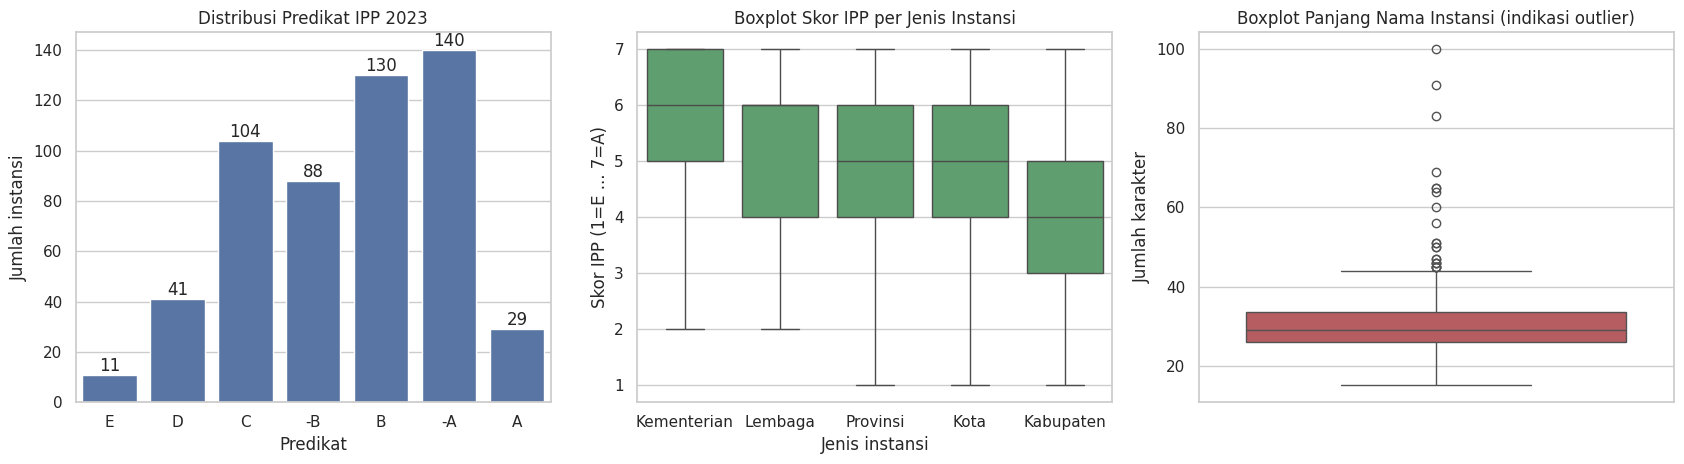

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.8))
order = ["E","D","C","-B","B","-A","A"]
sns.countplot(data=df, x="ipp_predikat", order=order, ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribusi Predikat IPP 2023"); ax[0].set_xlabel("Predikat"); ax[0].set_ylabel("Jumlah instansi")
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

sns.boxplot(data=df, x="jenis", y="skor_ipp", order=["Kementerian","Lembaga","Provinsi","Kota","Kabupaten"], ax=ax[1], color="#55A868")
ax[1].set_title("Boxplot Skor IPP per Jenis Instansi"); ax[1].set_xlabel("Jenis instansi"); ax[1].set_ylabel("Skor IPP (1=E ... 7=A)")

sns.boxplot(y=df["panjang_nama"], ax=ax[2], color="#C44E52")
ax[2].set_title("Boxplot Panjang Nama Instansi (indikasi outlier)"); ax[2].set_ylabel("Jumlah karakter")
plt.tight_layout(); plt.savefig("insight_ipp.png", dpi=150); plt.show()

### 1d. Data Preparation

In [ ]:
print("Missing value sebelum:", df.isna().sum().sum())
df = df.dropna(subset=["nama","ipp_predikat"])            # target tidak boleh kosong -> hapus
df["panjang_nama"] = df["panjang_nama"].fillna(df["panjang_nama"].median())  # fitur numerik -> median
df = df.drop_duplicates(subset="nama")

lo, hi = iqr_bounds(df["panjang_nama"])
n_cap = (df["panjang_nama"]>hi).sum()
df["panjang_nama_cap"] = df["panjang_nama"].clip(upper=hi)
df["jumlah_kata_cap"]  = df["jumlah_kata"].clip(upper=iqr_bounds(df["jumlah_kata"])[1])
print(f"Batas atas IQR = {hi:.2f}; nilai di-cap: {n_cap} baris")

# 3) Hapus kolom konstan (tahun = 2023 seluruhnya), simpan data bersih
df_clean = df.drop(columns=["tahun"])
df_clean.to_csv("ipp_2023_clean.csv", index=False)
print("\nKondisi akhir:", df_clean.shape, "| missing:", df_clean.isna().sum().sum())
df_clean.head()

Missing value sebelum: 0
Batas atas IQR = 44.75; nilai di-cap: 22 baris

Kondisi akhir: (543, 9) | missing: 0


,nama,ipp_predikat,skor_ipp,jenis,is_pusat,panjang_nama,jumlah_kata,panjang_nama_cap,jumlah_kata_cap
0,Arsip Nasional Republik Indonesia,B,5,Lembaga,1,33,4,33.00,4.0
1,Badan Informasi Geospasial,-A,6,Lembaga,1,26,3,26.00,3.0
2,"Badan Meteorologi, Klimatologi, dan Geofisika",D,2,Lembaga,1,45,5,44.75,5.0
3,Badan Narkotika Nasional,-B,4,Lembaga,1,24,3,24.00,3.0
4,Badan Nasional Penanggulangan Bencana,B,5,Lembaga,1,37,4,37.00,4.0


## SOAL 2 — Verifikasi Perhitungan Manual (Regresi Linier Sederhana)
Sampel 8 baris (stratified: 4 instansi pusat + 4 pemda), fitur **x = is_pusat** (1 = Kementerian/Lembaga, 0 = Pemda), target **y = skor_ipp**.

In [8]:
sampel = pd.concat([
    df_clean[df_clean.is_pusat==1].sample(4, random_state=42),
    df_clean[df_clean.is_pusat==0].sample(4, random_state=42),
])[["nama","ipp_predikat","is_pusat","skor_ipp"]].reset_index(drop=True)
x = sampel["is_pusat"].values.astype(float); y = sampel["skor_ipp"].values.astype(float)
n = len(x); xb, yb = x.mean(), y.mean()
Sxy = ((x-xb)*(y-yb)).sum(); Sxx = ((x-xb)**2).sum()
b1 = Sxy/Sxx; b0 = yb - b1*xb
yhat = b0 + b1*x
SSE = ((y-yhat)**2).sum(); SST = ((y-yb)**2).sum()
display(sampel)
print(f"n={n}  x_bar={xb}  y_bar={yb}")
print(f"Sxy={Sxy:.4f}  Sxx={Sxx:.4f}")
print(f"b1 = Sxy/Sxx = {b1:.4f}\nb0 = y_bar - b1*x_bar = {b0:.4f}")
print(f"SSE={SSE:.4f}  SST={SST:.4f}  R2={1-SSE/SST:.4f}  MSE={SSE/n:.4f}  RMSE={np.sqrt(SSE/n):.4f}")
# verifikasi dengan sklearn
m = LinearRegression().fit(x.reshape(-1,1), y); print("Cek sklearn -> b0:", round(m.intercept_,4), " b1:", round(m.coef_[0],4))

,nama,ipp_predikat,is_pusat,skor_ipp
0,Kementerian Energi dan Sumber Daya Mineral,B,1,5
1,Arsip Nasional Republik Indonesia,B,1,5
2,Kementerian Sekretariat Negara,-A,1,6
3,Badan Nasional Penanggulangan Bencana,B,1,5
4,Pemerintah Kabupaten Blora,-A,0,6
5,Pemerintah Kabupaten Buru,D,0,2
6,Pemerintah Kabupaten Barito Kuala,B,0,5
7,Pemerintah Kota Depok,B,0,5


n=8  x_bar=0.5  y_bar=4.875
Sxy=1.5000  Sxx=2.0000
b1 = Sxy/Sxx = 0.7500
b0 = y_bar - b1*x_bar = 4.5000
SSE=9.7500  SST=10.8750  R2=0.1034  MSE=1.2188  RMSE=1.1040
Cek sklearn -> b0: 4.5  b1: 0.75


## SOAL 3 — Implementasi Model Regresi Linier (Python)

In [ ]:
y = df_clean["skor_ipp"]
X_simple = df_clean[["is_pusat"]]
X_full = pd.concat([pd.get_dummies(df_clean["jenis"], prefix="jenis", drop_first=True).astype(int),
                    df_clean[["panjang_nama_cap","jumlah_kata_cap"]]], axis=1)
print("Fitur model lengkap:", list(X_full.columns))

idx_tr, idx_te = train_test_split(df_clean.index, test_size=0.2, random_state=42, stratify=df_clean["jenis"])
ytr, yte = y.loc[idx_tr], y.loc[idx_te]

def evaluasi(nama, model, X):
    model.fit(X.loc[idx_tr], ytr)
    pred = model.predict(X.loc[idx_te])
    cv = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    return {"Model":nama,
            "MAE":mean_absolute_error(yte,pred),
            "RMSE":np.sqrt(mean_squared_error(yte,pred)),
            "R2 (test)":r2_score(yte,pred),
            "R2 (CV 5-fold)":cv.mean(),
            "Akurasi ±1 tingkat":(np.abs(np.round(pred)-yte)<=1).mean()}, pred

base_pred = np.full(len(yte), ytr.mean())
hasil = [{"Model":"Baseline (rata-rata)","MAE":mean_absolute_error(yte,base_pred),
          "RMSE":np.sqrt(mean_squared_error(yte,base_pred)),"R2 (test)":r2_score(yte,base_pred),
          "R2 (CV 5-fold)":np.nan,"Akurasi ±1 tingkat":(np.abs(np.round(base_pred)-yte)<=1).mean()}]
r1, _ = evaluasi("Regresi Linier (is_pusat)", LinearRegression(), X_simple); hasil.append(r1)
lr = LinearRegression(); r2, pred_full = evaluasi("Regresi Linier (fitur lengkap)", lr, X_full); hasil.append(r2)
tabel = pd.DataFrame(hasil).round(4); tabel

Fitur model lengkap: ['jenis_Kementerian', 'jenis_Kota', 'jenis_Lembaga', 'jenis_Provinsi', 'panjang_nama_cap', 'jumlah_kata_cap']


,Model,MAE,RMSE,R2 (test),R2 (CV 5-fold),Akurasi ±1 tingkat
0,Baseline (rata-rata),1.3660,1.5799,-0.0123,NaN,0.4954
1,Regresi Linier (is_pusat),1.3172,1.5400,0.0382,0.0441,0.5413
2,Regresi Linier (fitur lengkap),1.2459,1.4924,0.0967,0.0845,0.6422


Intercept: 5.2511
Koefisien:
 jenis_Kementerian    1.5679
jenis_Kota           0.5510
jenis_Lembaga        1.0551
jenis_Provinsi       0.8708
panjang_nama_cap    -0.0049
jumlah_kata_cap     -0.2681
dtype: float64


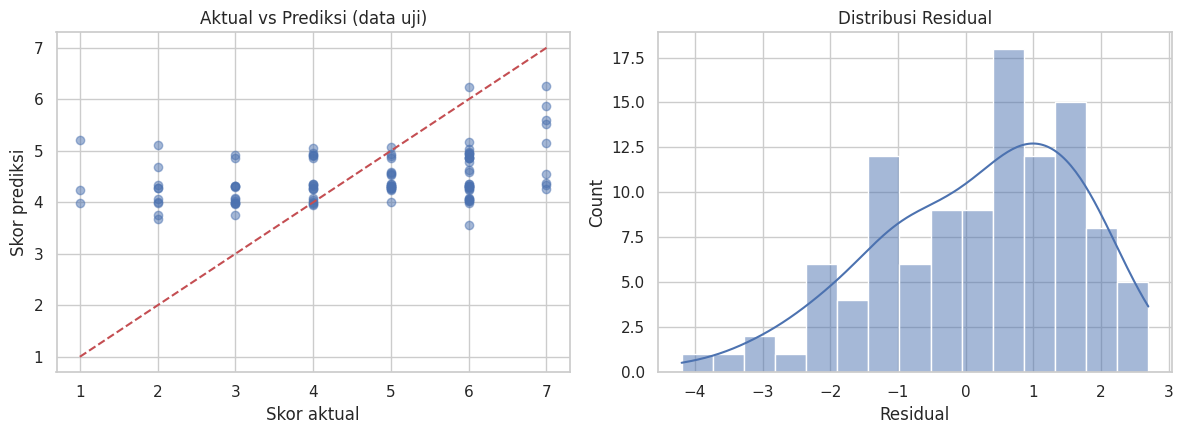

In [10]:
koef = pd.Series(lr.coef_, index=X_full.columns).round(4)
print("Intercept:", round(lr.intercept_,4)); print("Koefisien:\n", koef)

fig, ax = plt.subplots(1,2, figsize=(12,4.5))
ax[0].scatter(yte, pred_full+np.random.default_rng(0).normal(0,.04,len(yte)), alpha=.5)
ax[0].plot([1,7],[1,7],"r--"); ax[0].set_xlabel("Skor aktual"); ax[0].set_ylabel("Skor prediksi"); ax[0].set_title("Aktual vs Prediksi (data uji)")
sns.histplot(yte-pred_full, bins=15, kde=True, ax=ax[1]); ax[1].set_title("Distribusi Residual"); ax[1].set_xlabel("Residual")
plt.tight_layout(); plt.savefig("evaluasi_model.png", dpi=150); plt.show()

## Kesimpulan
Lihat tabel evaluasi di atas. Jenis instansi memiliki hubungan dengan skor IPP (instansi pusat cenderung lebih tinggi, Kabupaten paling rendah), namun karena dataset hanya memuat nama dan predikat, kekuatan prediksi model bersifat terbatas. Untuk model yang lebih kuat, perlu ditambahkan variabel numerik seperti nilai komponen IPP, anggaran, jumlah penduduk, atau indeks digitalisasi layanan.